# City Lifestyle Segmentation Using Unsupervised Machine Learning

### Objective
Group cities into **data-driven lifestyle profiles** using socioeconomic, connectivity, environmental and quality-of-life indicators.

The key idea is **unsupervised learning**: the clustering algorithms do **not** use the `country` or any pre-existing lifestyle label to form the clusters.

### Questions we want to answer
1. What structure exists in the city-level variables?
2. How many clusters are reasonably supported by the data?
3. Which clustering method gives the most useful segmentation?
4. What characteristics define each cluster?
5. Are the discovered clusters geographically concentrated?
6. Are the clustering results stable?

> **Dataset note:** The supplied starter notebook describes this as a synthetic city-lifestyle dataset. Therefore, the results should be interpreted as patterns **within this dataset**, not as claims about real-world cities in general.


## 1. Import libraries

We use only libraries that are directly relevant to the analysis:
- `pandas`, `numpy` for data handling
- `matplotlib` for visualisation
- `scikit-learn` for scaling, PCA and clustering
- `scipy` for hierarchical clustering and the post-clustering chi-square test


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = False


## 2. Load the dataset

The notebook is designed to run locally with the uploaded CSV. If you move the notebook elsewhere, change `DATA_PATH` accordingly.


In [2]:
DATA_PATH = "city_lifestyle_dataset.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())


Dataset shape: 300 rows × 10 columns


,city_name,country,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
0,Old Vista,Europe,2775,3850,86.4,1310,43,52.0,8.5,23.8
1,Beachport,Europe,3861,3700,78.1,1330,42,62.8,8.1,33.1
2,Valleyborough,Europe,2562,4310,80.1,1330,39,73.2,8.5,40.2
3,City,Europe,3192,3970,81.2,1480,60,49.2,8.5,43.6
4,Falls,Europe,3496,4320,100.0,1510,64,93.7,8.5,42.5


## 3. Understand the variables

`city_name` and `country` are **descriptive categorical variables**. They are not used as clustering inputs.

The remaining eight variables are numerical and describe city characteristics:
- population density
- average income
- internet penetration
- average rent
- air quality index
- public transport score
- happiness score
- green-space ratio

There is no supervised target variable here. That is important: we are **discovering groups**, rather than predicting a known class.


In [3]:
df.info()

print("\nSummary statistics:")
display(df.describe().T.round(2))

print("\nSkewness (checking for heavily one-sided distributions before scaling):")
display(df.select_dtypes(include=[np.number]).skew().round(2).to_frame("skew"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nUnique countries/regions:")
print(df["country"].nunique())
print(df["country"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city_name               300 non-null    object 
 1   country                 300 non-null    object 
 2   population_density      300 non-null    int64  
 3   avg_income              300 non-null    int64  
 4   internet_penetration    300 non-null    float64
 5   avg_rent                300 non-null    int64  
 6   air_quality_index       300 non-null    int64  
 7   public_transport_score  300 non-null    float64
 8   happiness_score         300 non-null    float64
 9   green_space_ratio       300 non-null    float64
dtypes: float64(4), int64(4), object(2)
memory usage: 23.6+ KB

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
population_density,300.0,3944.84,2982.57,100.0,1830.00,3083.5,4823.75,14427.0
avg_income,300.0,2827.20,1201.16,480.0,1907.50,2810.0,3752.50,5720.0
internet_penetration,300.0,74.31,17.01,34.0,64.40,75.0,87.22,100.0
avg_rent,300.0,1002.77,456.28,170.0,640.00,990.0,1332.50,2430.0
air_quality_index,300.0,71.25,25.34,22.0,54.00,67.5,86.00,146.0
public_transport_score,300.0,55.72,14.71,15.0,46.08,54.7,64.20,95.0
happiness_score,300.0,6.64,1.69,2.5,5.30,6.9,8.50,8.5
green_space_ratio,300.0,33.99,9.43,2.0,28.22,34.7,40.40,58.0



Skewness (checking for heavily one-sided distributions before scaling):


,skew
population_density,1.33
avg_income,-0.01
internet_penetration,-0.27
avg_rent,0.21
air_quality_index,0.63
public_transport_score,0.31
happiness_score,-0.41
green_space_ratio,-0.25



Missing values:


,missing_values
city_name,0
country,0
population_density,0
avg_income,0
internet_penetration,0
avg_rent,0
air_quality_index,0
public_transport_score,0
happiness_score,0
green_space_ratio,0



Unique countries/regions:
6
country
Asia             80
Europe           60
North America    50
South America    40
Africa           35
Oceania          35
Name: count, dtype: int64


### Data-quality interpretation

The supplied dataset contains **300 observations and 10 columns**. There are no missing values in the supplied CSV.

For clustering, we will use only the eight numerical lifestyle variables. `city_name` is an identifier, while `country` is kept for **post-clustering interpretation only**.

`population_density` is noticeably right-skewed (skew ≈ 1.33, max ≈ 4.7× the median). K-Means does not require normally-distributed features, so we keep it as it is rather than transforming it, but it is worth remembering this when interpreting the high-density cluster later — that cluster's separation could partly reflect a handful of extreme cities rather than a smooth density gradient.


In [4]:
numeric_cols = [
    "population_density",
    "avg_income",
    "internet_penetration",
    "avg_rent",
    "air_quality_index",
    "public_transport_score",
    "happiness_score",
    "green_space_ratio"
]

X_raw = df[numeric_cols].copy()

missing_expected = [c for c in numeric_cols if c not in df.columns]
if missing_expected:
    raise ValueError(f"Missing expected columns: {missing_expected}")

if X_raw.isna().any().any():
    raise ValueError("Missing values detected in clustering variables. Handle them before clustering.")

print("Clustering variables:")
print(numeric_cols)


Clustering variables:
['population_density', 'avg_income', 'internet_penetration', 'avg_rent', 'air_quality_index', 'public_transport_score', 'happiness_score', 'green_space_ratio']


## 4. Exploratory Data Analysis

Before clustering, we check data quality and the relationships among the numerical lifestyle variables.

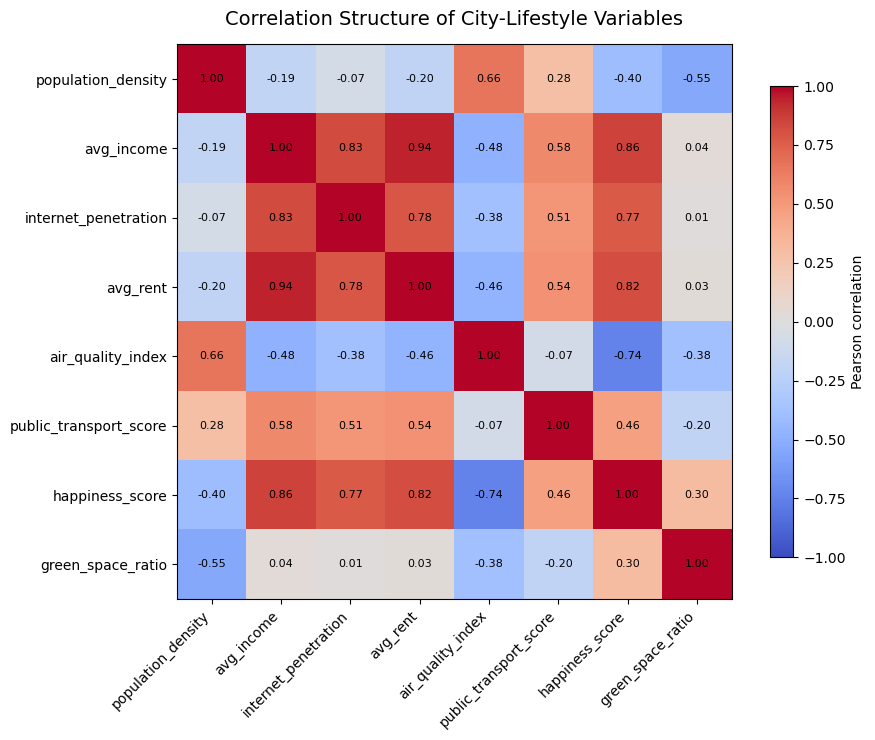

Strongest relationships:


correlation
avg_income           avg_rent                    0.942
                     happiness_score             0.858
                     internet_penetration        0.825
avg_rent             happiness_score             0.815
internet_penetration avg_rent                    0.781
                     happiness_score             0.770

In [5]:
corr = X_raw.corr()

fig, ax = plt.subplots(figsize=(9.5, 7.5))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticklabels(numeric_cols)
ax.set_title("Correlation Structure of City-Lifestyle Variables", fontsize=14, pad=14)

for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8)

cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Pearson correlation")

plt.tight_layout()
plt.show()

pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .sort_values(key=np.abs, ascending=False)
)

print("Strongest relationships:")
display(pairs.head(6).to_frame("correlation").round(3))


## 5. Standardise the clustering variables

K-Means and hierarchical clustering are distance-based methods. A variable measured on a large numerical scale could otherwise dominate the distance calculation.

We therefore use z-score standardisation:

z = (x - x̄) / s

After scaling, each feature has mean approximately 0 and standard deviation approximately 1.


In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled_df = pd.DataFrame(X_scaled, columns=numeric_cols)

print("Means after scaling:")
display(X_scaled_df.mean().round(6).to_frame("mean"))

print("Standard deviations after scaling:")
display(X_scaled_df.std(ddof=0).round(6).to_frame("std"))


Means after scaling:


,mean
population_density,0.0
avg_income,0.0
internet_penetration,0.0
avg_rent,0.0
air_quality_index,-0.0
public_transport_score,0.0
happiness_score,-0.0
green_space_ratio,0.0


Standard deviations after scaling:


,std
population_density,1.0
avg_income,1.0
internet_penetration,1.0
avg_rent,1.0
air_quality_index,1.0
public_transport_score,1.0
happiness_score,1.0
green_space_ratio,1.0


## 6. PCA for dimensionality reduction and interpretation

PCA is **not the clustering algorithm** here.

We use PCA for two purposes:
1. quantify how much of the overall variation can be represented by a smaller number of components;
2. create a two-dimensional map for visualising the final clusters.

We fit PCA on the **standardised numerical variables**, not on `country` or `city_name`.


In [21]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

pca_summary = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, len(explained) + 1)],
    "Explained_variance": explained,
    "Cumulative_variance": cumulative
})

display(pca_summary.round(4))

,PC,Explained_variance,Cumulative_variance
0,PC1,0.5381,0.5381
1,PC2,0.2583,0.7964
2,PC3,0.0733,0.8697
3,PC4,0.0545,0.9242
4,PC5,0.0363,0.9605
5,PC6,0.0248,0.9853
6,PC7,0.0089,0.9941
7,PC8,0.0059,1.0000


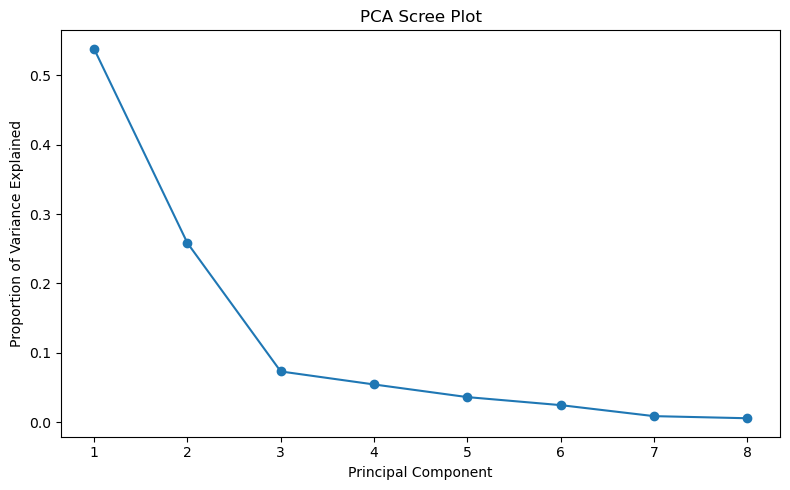

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    range(1, len(explained) + 1),
    explained,
    marker="o"
)

ax.set_xlabel("Principal Component")
ax.set_ylabel("Proportion of Variance Explained")
ax.set_title("PCA Scree Plot")
ax.set_xticks(range(1, len(explained) + 1))

plt.tight_layout()
plt.show()

### PCA interpretation

The scree plot shows a pronounced decline in explained variance from PC1 to PC3, after which the curve begins to flatten considerably. This suggests that the first three principal components capture the major structure in the data, while subsequent components contribute relatively little additional variance. Therefore, three principal components are retained according to the scree-plot criterion.

Next we inspect the loadings to understand what the components represent.


In [23]:
# Loading matrix for the retained principal components
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=numeric_cols,
    columns=[f"PC{i}" for i in range(1, len(numeric_cols) + 1)]
)

# Display loadings for the 3 retained PCs
display(loadings[["PC1", "PC2", "PC3"]].round(3))

# Find the 5 variables with the largest absolute loadings for each retained PC
largest_loadings = pd.DataFrame({
    "PC1": loadings["PC1"].abs().sort_values(ascending=False).head(5).index,
    "PC2": loadings["PC2"].abs().sort_values(ascending=False).head(5).index,
    "PC3": loadings["PC3"].abs().sort_values(ascending=False).head(5).index
})

# Add the corresponding loading values in parentheses
for pc in ["PC1", "PC2", "PC3"]:
    largest_loadings[pc] = largest_loadings[pc].apply(
        lambda var: f"{var} ({loadings.loc[var, pc]:.3f})"
    )

print("Variables with the largest absolute loadings:")
display(largest_loadings)


,PC1,PC2,PC3
population_density,-0.177,0.575,0.256
avg_income,0.453,0.145,-0.048
internet_penetration,0.407,0.186,0.018
avg_rent,0.441,0.136,-0.091
air_quality_index,-0.330,0.373,0.323
public_transport_score,0.264,0.428,0.399
happiness_score,0.463,-0.078,0.038
green_space_ratio,0.103,-0.517,0.811


Variables with the largest absolute loadings:


,PC1,PC2,PC3
0,happiness_score (0.463),population_density (0.575),green_space_ratio (0.811)
1,avg_income (0.453),green_space_ratio (-0.517),public_transport_score (0.399)
2,avg_rent (0.441),public_transport_score (0.428),air_quality_index (0.323)
3,internet_penetration (0.407),air_quality_index (0.373),population_density (0.256)
4,air_quality_index (-0.330),internet_penetration (0.186),avg_rent (-0.091)


### What the loadings tell us

The loading matrix helps us understand which variables contribute most strongly to each of the three retained principal components.

- **PC1:** The largest loadings are for `happiness_score` (0.463), `avg_income` (0.453), `avg_rent` (0.441), and `internet_penetration` (0.407), with `air_quality_index` having a negative loading (-0.330). Thus, PC1 broadly represents an **economic, connectivity and quality-of-life dimension**, with better air quality associated with the opposite direction of the component.

- **PC2:** The largest loadings are for `population_density` (0.575), `green_space_ratio` (-0.517), `public_transport_score` (0.428), and `air_quality_index` (0.373). Thus, PC2 broadly represents an **urban density and environmental dimension**, with population density and public transport contributing positively, while green-space ratio contributes negatively.

- **PC3:** The largest loading is for `green_space_ratio` (0.811), followed by `public_transport_score` (0.399), `air_quality_index` (0.323), and `population_density` (0.256). Therefore, PC3 is primarily an **environmental/green-space dimension**, with additional contributions from public transport, air quality and population density.

The **magnitude** of a loading indicates how strongly a variable contributes to a principal component, while its **sign** indicates the direction of its relationship with that component. These interpretations describe the dominant patterns in the data rather than treating a principal component as a literal real-world variable.

## 7. How many clusters?

Choosing `n_clusters=4` simply because it looks reasonable would be arbitrary.

We compare K = 2 to 8 using three internal validation measures:

- **Silhouette:** higher is better.
- **Davies–Bouldin:** lower is better.
- **Calinski–Harabasz:** higher is better.

We use the metrics together and then consider whether the resulting groups are interpretable.


In [9]:
k_values = range(2, 9)
k_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = model.fit_predict(X_scaled)

    k_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, labels)
    })

k_results = pd.DataFrame(k_results)

display(k_results.round(4))


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,1411.0539,0.3555,1.1119,208.8552
1,3,1036.5915,0.3562,1.1027,195.3191
2,4,890.3518,0.2710,1.2198,167.2956
3,5,811.6959,0.2297,1.3582,144.3120
4,6,749.6157,0.2029,1.4595,129.4565
5,7,697.8957,0.1974,1.5445,119.1001
6,8,651.6034,0.1951,1.4722,111.9287


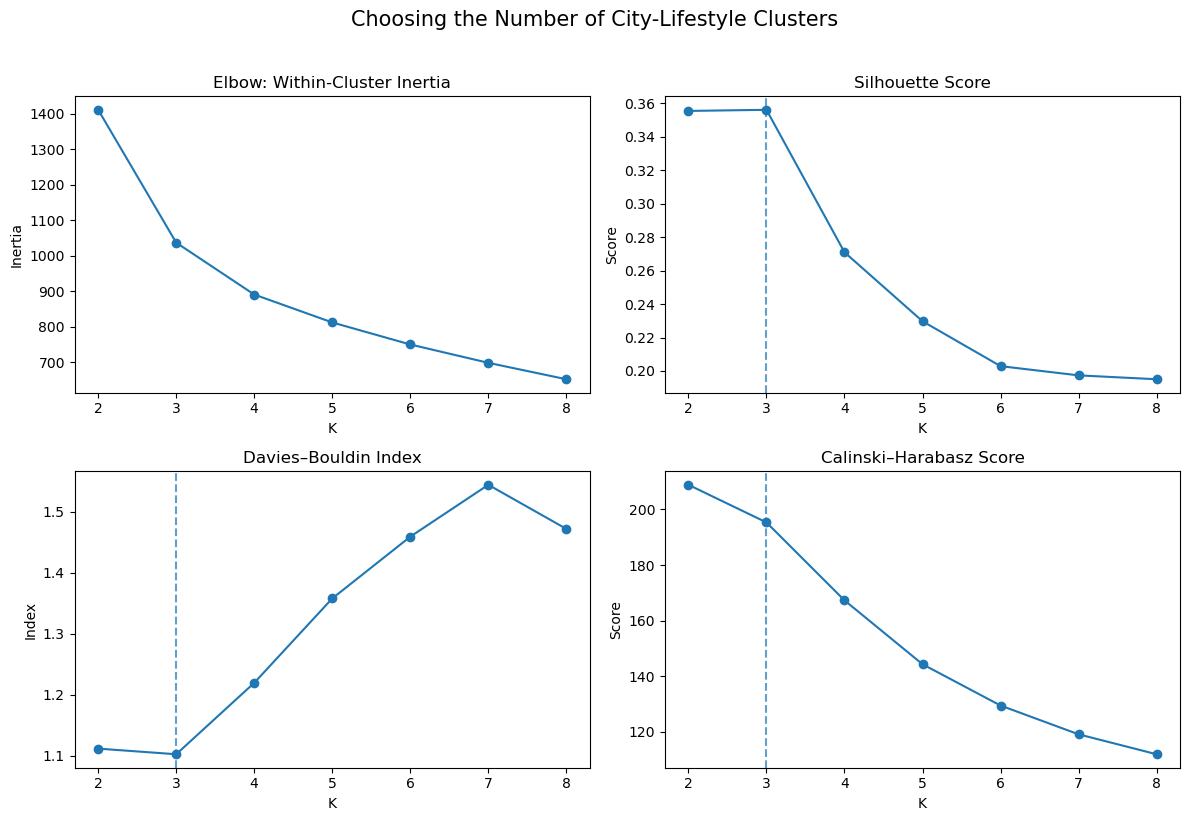

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(k_results["k"], k_results["inertia"], marker="o")
axes[0, 0].set_title("Elbow: Within-Cluster Inertia")
axes[0, 0].set_xlabel("K")
axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(k_results["k"], k_results["silhouette"], marker="o")
axes[0, 1].axvline(3, linestyle="--", alpha=0.7)
axes[0, 1].set_title("Silhouette Score")
axes[0, 1].set_xlabel("K")
axes[0, 1].set_ylabel("Score")

axes[1, 0].plot(k_results["k"], k_results["davies_bouldin"], marker="o")
axes[1, 0].axvline(3, linestyle="--", alpha=0.7)
axes[1, 0].set_title("Davies–Bouldin Index")
axes[1, 0].set_xlabel("K")
axes[1, 0].set_ylabel("Index")

axes[1, 1].plot(k_results["k"], k_results["calinski_harabasz"], marker="o")
axes[1, 1].axvline(3, linestyle="--", alpha=0.7)
axes[1, 1].set_title("Calinski–Harabasz Score")
axes[1, 1].set_xlabel("K")
axes[1, 1].set_ylabel("Score")

fig.suptitle("Choosing the Number of City-Lifestyle Clusters", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()


### Decision: K = 3

The validation metrics indicate that **K=2 and K=3 are the strongest candidates**, while larger K values fragment the data and reduce cluster quality. The three metrics do not unanimously agree: silhouette is highest at K=3 (0.3562 vs 0.3555), Davies-Bouldin is also marginally better at K=3, but Calinski-Harabasz is clearly higher at K=2 (208.9 vs 195.3). We do not treat this as a tie-break in K=3's favour by the numbers alone — we choose K=3 for the substantive reason below.

K=2 gives a very broad split. **K=3 adds a distinct high-density urban profile**, making it more useful for the project's objective of city-lifestyle segmentation.

Therefore, we use **K=3 as the main solution**, while acknowledging that K=2 is a close statistical alternative.


## 8. Final K-Means model

We now fit the selected K=3 model.

`n_init=50` means K-Means is run from multiple initial centroid configurations and the best solution is retained, reducing sensitivity to a single random initialisation.


In [11]:
FINAL_K = 3

kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=50
)

cluster_labels = kmeans.fit_predict(X_scaled)
df["cluster"] = cluster_labels

final_metrics = {
    "Silhouette": silhouette_score(X_scaled, cluster_labels),
    "Davies-Bouldin": davies_bouldin_score(X_scaled, cluster_labels),
    "Calinski-Harabasz": calinski_harabasz_score(X_scaled, cluster_labels)
}

print("Final K-Means validation metrics:")
for name, value in final_metrics.items():
    print(f"{name}: {value:.4f}")

print("\nCluster sizes:")
display(df["cluster"].value_counts().sort_index().rename("number_of_cities").to_frame())


Final K-Means validation metrics:
Silhouette: 0.3562
Davies-Bouldin: 1.1027
Calinski-Harabasz: 195.3191

Cluster sizes:


,number_of_cities
cluster,
0,85
1,143
2,72


## 9. Visualise the clusters in PCA space

The clustering itself was performed in the **full eight-dimensional standardised feature space**, using all eight original clustering variables.

Based on the scree plot, the **first three principal components were retained** as they capture the major structure in the data. The loadings of PC1, PC2 and PC3 were examined to interpret these components.

The plots below provide visual representations of the final K-Means clusters in this reduced PCA space:

- The **2D plot** shows the clusters along **PC1 and PC2**. These two components explain approximately **79.6% of the total standardised-feature variance**, making the 2D projection useful for visualising the overall cluster separation.
- The **3D plot** shows the clusters along **PC1, PC2 and PC3**, thereby visualising all three retained principal components.

In both plots, PCA is used **only for visualisation** and the K-Means algorithm itself was fitted using all eight standardised variables.

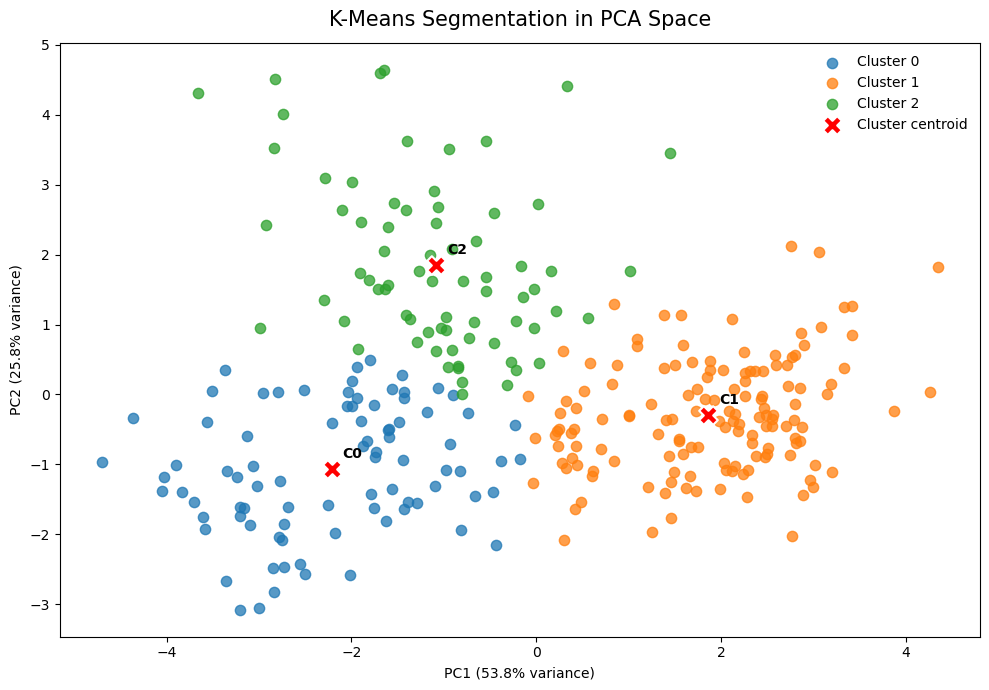

In [32]:
# Use the three retained principal components
pca_df = pd.DataFrame(
    X_pca_full[:, :3],
    columns=["PC1", "PC2", "PC3"]
)

# 2D visualisation using PC1 and PC2

fig, ax = plt.subplots(figsize=(10, 7))

for cluster in sorted(np.unique(cluster_labels)):
    mask = cluster_labels == cluster
    
    ax.scatter(
        pca_df.loc[mask, "PC1"],
        pca_df.loc[mask, "PC2"],
        s=55,
        alpha=0.75,
        label=f"Cluster {cluster}"
    )

# Project the K-Means centroids into PCA space
centroids_pca = pca_full.transform(kmeans.cluster_centers_)

# Plot centroids as large red X markers
ax.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=180,
    color="red",
    edgecolor="white",
    linewidth=1.5,
    label="Cluster centroid"
)

# Label the centroids
for c in range(kmeans.n_clusters):
    ax.annotate(
        f"C{c}",
        (centroids_pca[c, 0], centroids_pca[c, 1]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "K-Means Segmentation in PCA Space",
    fontsize=15,
    pad=12
)

ax.set_xlabel(
    f"PC1 ({pca_full.explained_variance_ratio_[0] * 100:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({pca_full.explained_variance_ratio_[1] * 100:.1f}% variance)"
)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

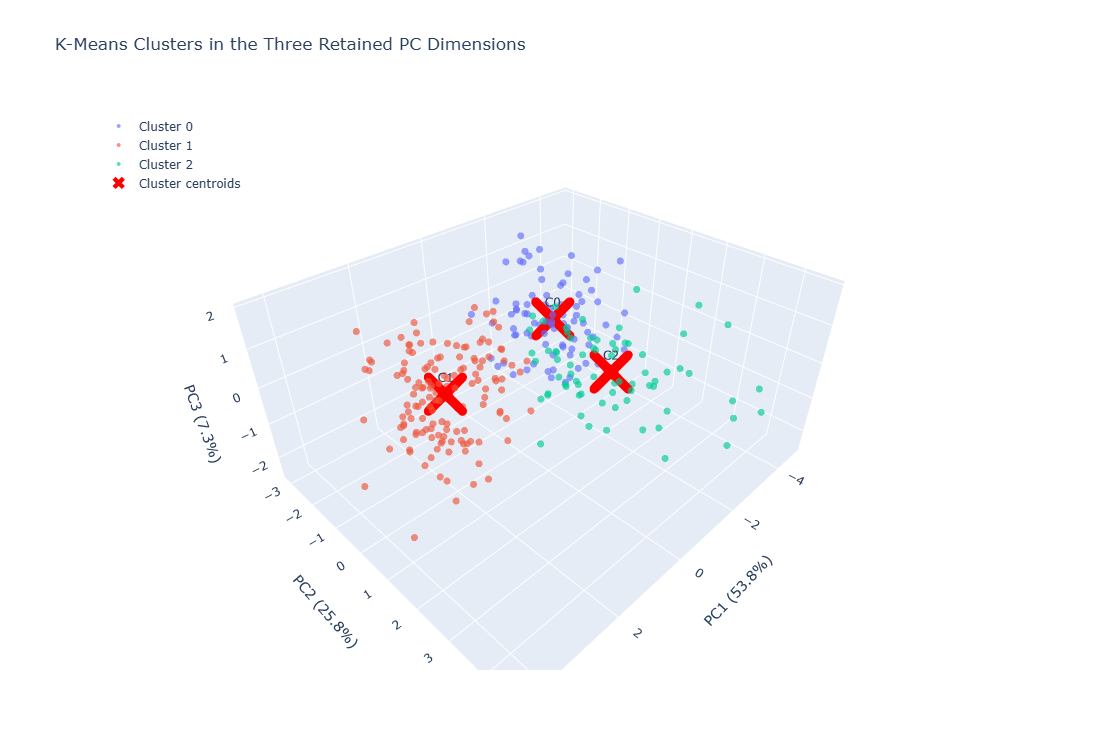

In [35]:
import plotly.graph_objects as go

fig = go.Figure()

# Add each cluster separately so the colours are categorical
for cluster in sorted(np.unique(cluster_labels)):
    
    mask = cluster_labels == cluster
    
    fig.add_trace(
        go.Scatter3d(
            x=pca_df.loc[mask, "PC1"],
            y=pca_df.loc[mask, "PC2"],
            z=pca_df.loc[mask, "PC3"],
            mode="markers",
            name=f"Cluster {cluster}",
            marker=dict(
                size=4,
                opacity=0.65
            ),
            text=pca_df.loc[mask, "city"],
            hovertemplate=(
                "<b>%{text}</b><br>"
                "PC1: %{x:.2f}<br>"
                "PC2: %{y:.2f}<br>"
                "PC3: %{z:.2f}"
                "<extra></extra>"
            )
        )
    )

# Project K-Means centroids into the 3-PC space
centroids_pca = pca_full.transform(kmeans.cluster_centers_)

fig.add_trace(
    go.Scatter3d(
        x=centroids_pca[:, 0],
        y=centroids_pca[:, 1],
        z=centroids_pca[:, 2],
        mode="markers+text",
        name="Cluster centroids",
        marker=dict(
            size=11,
            color="red",
            symbol="x"
        ),
        text=[f"C{i}" for i in range(kmeans.n_clusters)],
        textposition="top center",
        hovertemplate=(
            "<b>%{text}</b><br>"
            "PC1: %{x:.2f}<br>"
            "PC2: %{y:.2f}<br>"
            "PC3: %{z:.2f}"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title="K-Means Clusters in the Three Retained PC Dimensions",
    width=1000,
    height=750,
    legend=dict(
        x=0.02,
        y=0.98
    ),
    scene=dict(
        xaxis_title=f"PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)",
        yaxis_title=f"PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)",
        zaxis_title=f"PC3 ({pca_full.explained_variance_ratio_[2]*100:.1f}%)"
    )
)

fig.show()

## 10. Profile the clusters

Cluster numbers are arbitrary labels. **Cluster 0 is not inherently better or worse than Cluster 1.**

To interpret the groups, we compare their feature means and their standardised (z-score) means.

The z-score table is especially useful because all variables are put on the same scale. Values above 0 mean the cluster is above the overall dataset average for that feature; values below 0 mean it is below average.


,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
cluster,,,,,,,,
0,2991.33,1434.00,55.30,495.41,78.52,40.99,4.97,36.03
1,2367.34,3804.06,86.26,1361.54,53.76,60.76,8.15,37.08
2,8203.62,2531.81,73.00,889.17,97.39,63.09,5.63,25.46


Standardised cluster profiles (z-scores):


,population_density,avg_income,internet_penetration,avg_rent,air_quality_index,public_transport_score,happiness_score,green_space_ratio
cluster,,,,,,,,
0,-0.32,-1.16,-1.12,-1.11,0.29,-1.00,-1.0,0.22
1,-0.53,0.81,0.70,0.79,-0.69,0.34,0.9,0.33
2,1.43,-0.25,-0.08,-0.25,1.03,0.50,-0.6,-0.91


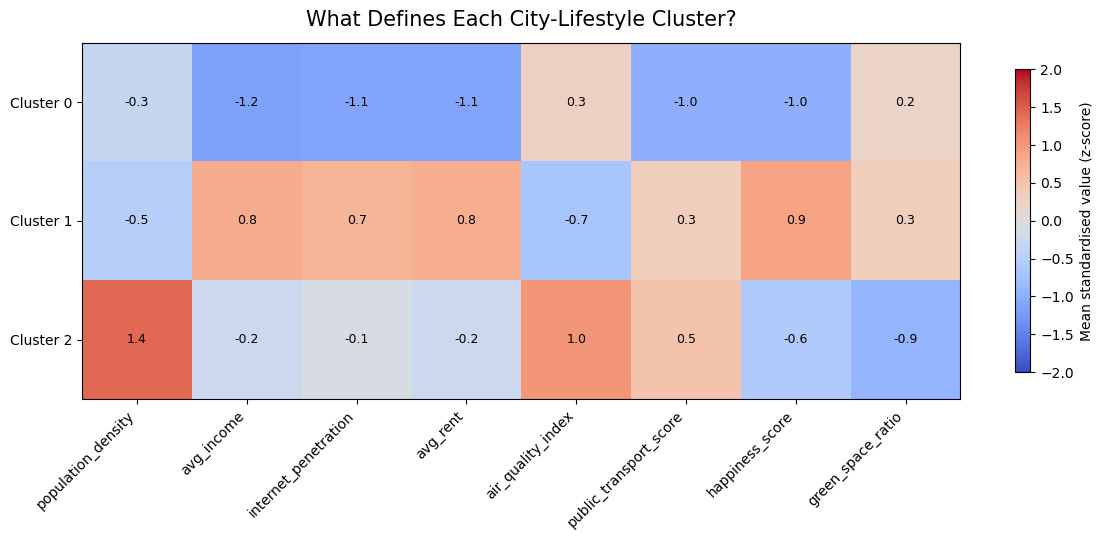

In [13]:
cluster_means = df.groupby("cluster")[numeric_cols].mean().round(2)
display(cluster_means)

cluster_z = pd.DataFrame(X_scaled, columns=numeric_cols).assign(cluster=cluster_labels)
cluster_z_means = cluster_z.groupby("cluster")[numeric_cols].mean().round(2)

print("Standardised cluster profiles (z-scores):")
display(cluster_z_means)

fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(
    cluster_z_means.values,
    aspect="auto",
    cmap="coolwarm",
    vmin=-2,
    vmax=2
)

ax.set_xticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticks(range(FINAL_K))
ax.set_yticklabels([f"Cluster {i}" for i in range(FINAL_K)])
ax.set_title("What Defines Each City-Lifestyle Cluster?", fontsize=15, pad=12)

for i in range(FINAL_K):
    for j in range(len(numeric_cols)):
        ax.text(
            j, i,
            f"{cluster_z_means.iloc[i, j]:.1f}",
            ha="center",
            va="center",
            fontsize=9
        )

cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label("Mean standardised value (z-score)")

plt.tight_layout()
plt.show()


### Cluster interpretation for this dataset

The three groups have clear profiles:

- **Cluster 0:** substantially lower income, internet penetration, rent, transport score and happiness, with lower population density than the overall mean.
- **Cluster 1:** higher income, internet penetration, rent, transport score and happiness, with relatively lower density.
- **Cluster 2:** by far the highest population density, with poorer air-quality values (higher AQI), lower green-space ratio and lower happiness than Cluster 1.

## 11. Hierarchical clustering

Hierarchical clustering provides a genuinely different clustering strategy.

We use **Ward's linkage**, which merges observations while attempting to minimise the increase in within-cluster variance.

This is useful as a robustness/comparison step: if a different algorithm produces a broadly similar structure, our interpretation is more convincing.


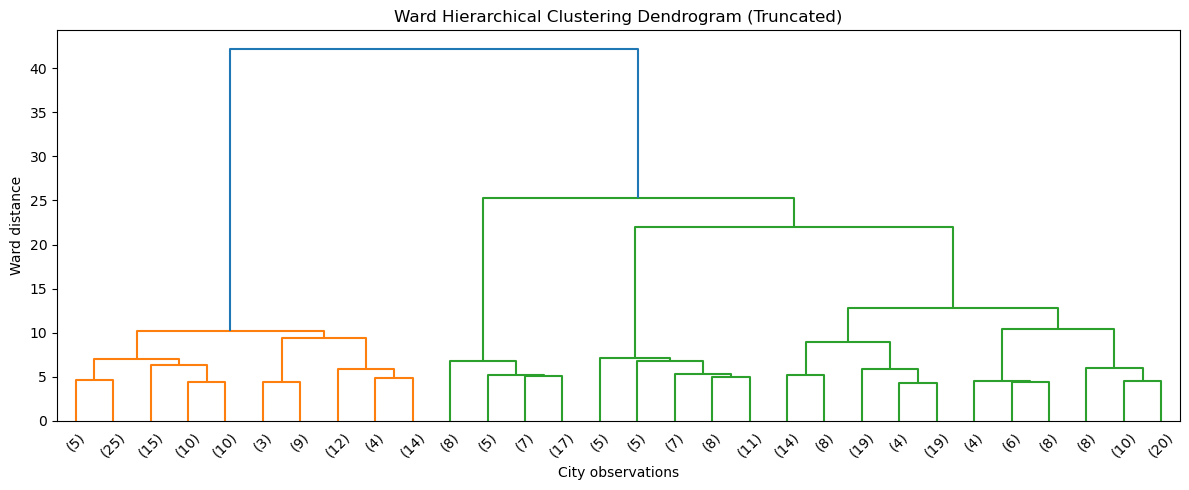

In [47]:
Z = linkage(X_scaled, method="ward")

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    ax=ax
)
ax.set_title("Ward Hierarchical Clustering Dendrogram (Truncated)")
ax.set_xlabel("City observations")
ax.set_ylabel("Ward distance")
plt.tight_layout()
plt.show()


### Choosing K for Ward

In [36]:
from sklearn.cluster import AgglomerativeClustering

# Evaluate the same range of K values used for K-Means
k_values = range(2, 9)

hierarchical_results = []

for k in k_values:
    # Ward hierarchical clustering
    ward = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    
    ward_labels = ward.fit_predict(X_scaled)

    # Internal validation metrics
    silhouette = silhouette_score(X_scaled, ward_labels)
    db_index = davies_bouldin_score(X_scaled, ward_labels)
    ch_index = calinski_harabasz_score(X_scaled, ward_labels)

    hierarchical_results.append({
        "K": k,
        "Silhouette": silhouette,
        "Davies-Bouldin": db_index,
        "Calinski-Harabasz": ch_index
    })

hierarchical_results_df = pd.DataFrame(hierarchical_results)

display(
    hierarchical_results_df.round(4)
)

,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,0.3152,1.1037,175.9972
1,3,0.2701,1.1330,150.9800
2,4,0.2656,1.1687,151.0776
3,5,0.2161,1.5310,130.6343
4,6,0.1696,1.5152,114.9101
5,7,0.1589,1.6817,105.1648
6,8,0.1692,1.5510,97.8899


In [37]:
best_ward_silhouette = hierarchical_results_df.loc[
    hierarchical_results_df["Silhouette"].idxmax()
]

best_ward_db = hierarchical_results_df.loc[
    hierarchical_results_df["Davies-Bouldin"].idxmin()
]

best_ward_ch = hierarchical_results_df.loc[
    hierarchical_results_df["Calinski-Harabasz"].idxmax()
]

print("Best Ward solution by Silhouette:")
display(best_ward_silhouette.to_frame().T.round(4))

print("Best Ward solution by Davies-Bouldin:")
display(best_ward_db.to_frame().T.round(4))

print("Best Ward solution by Calinski-Harabasz:")
display(best_ward_ch.to_frame().T.round(4))

Best Ward solution by Silhouette:


,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2.0,0.3152,1.1037,175.9972


Best Ward solution by Davies-Bouldin:


,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2.0,0.3152,1.1037,175.9972


Best Ward solution by Calinski-Harabasz:


,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2.0,0.3152,1.1037,175.9972


### Final Ward Clustering: Dendrogram and Cluster Cut

In [43]:
ward_final = AgglomerativeClustering(
    n_clusters=best_ward_k,
    linkage="ward"
)

ward_final_labels = ward_final.fit_predict(X_scaled)

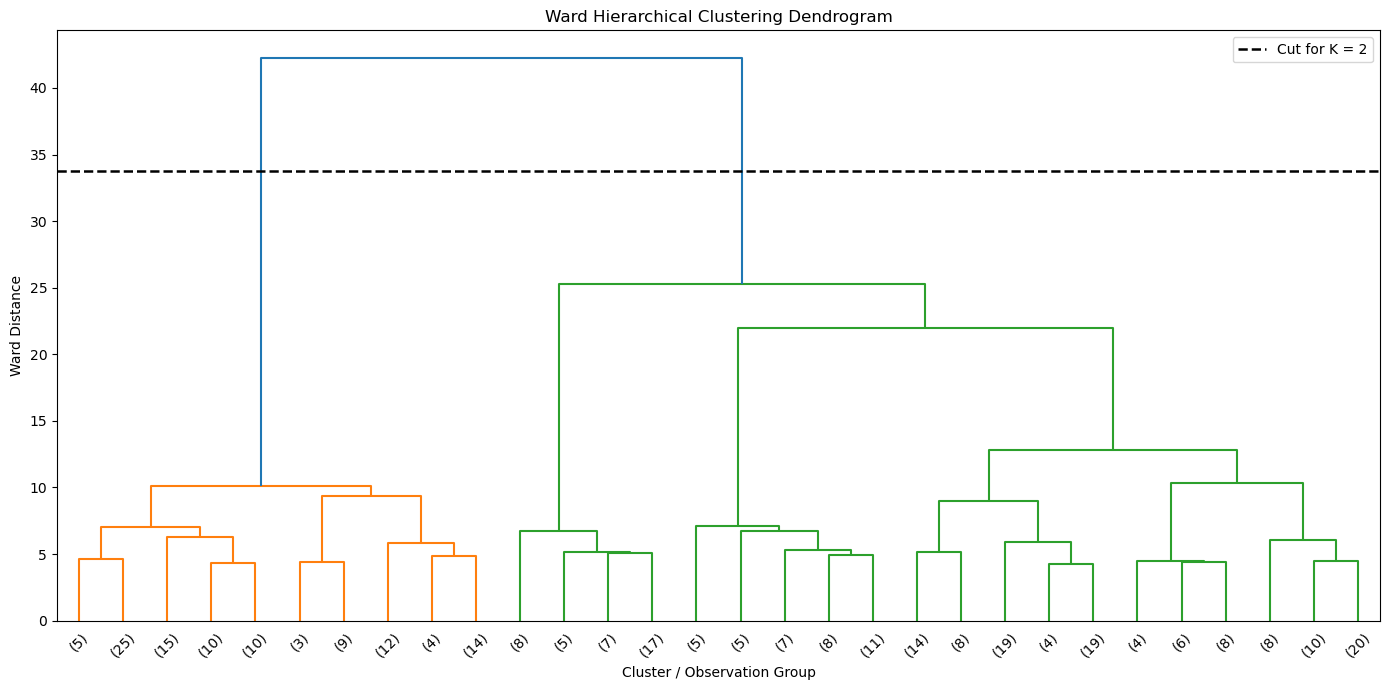

Ward cut height for K=2: 33.73


In [48]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Ward linkage
Z = linkage(X_scaled, method="ward")

# Ward's best number of clusters from validation
best_ward_k = int(best_ward["K"])

# For K = 2, the cut must lie between:
#   - the second-last merge
#   - the final merge
if best_ward_k == 2:
    cut_height = (Z[-2, 2] + Z[-1, 2]) / 2
else:
    raise ValueError("This cut calculation is currently set up for K=2.")

fig, ax = plt.subplots(figsize=(14, 7))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    ax=ax
)

# Add the actual horizontal cut
ax.axhline(
    y=cut_height,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Cut for K = {best_ward_k}"
)

ax.set_title("Ward Hierarchical Clustering Dendrogram")
ax.set_xlabel("Cluster / Observation Group")
ax.set_ylabel("Ward Distance")

ax.legend()

plt.tight_layout()
plt.show()

print(f"Ward cut height for K={best_ward_k}: {cut_height:.2f}")

## 12. Comparative Evaluation of Clustering Methods

In [39]:
# Prepare K-Means results
kmeans_comparison = k_results.copy()

# Rename columns to match the Ward results
kmeans_comparison = kmeans_comparison.rename(columns={
    "k": "K",
    "silhouette": "Silhouette",
    "davies_bouldin": "Davies-Bouldin",
    "calinski_harabasz": "Calinski-Harabasz"
})

kmeans_comparison["Method"] = "K-Means"


# Prepare Ward results
ward_comparison = hierarchical_results_df.copy()
ward_comparison["Method"] = "Ward Hierarchical"


# Keep only the columns needed for comparison
kmeans_comparison = kmeans_comparison[
    ["Method", "K", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
]

ward_comparison = ward_comparison[
    ["Method", "K", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
]


# Combine both methods
comparison_df = pd.concat(
    [kmeans_comparison, ward_comparison],
    ignore_index=True
)

display(comparison_df.round(4))

,Method,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,2,0.3555,1.1119,208.8552
1,K-Means,3,0.3562,1.1027,195.3191
2,K-Means,4,0.2710,1.2198,167.2956
3,K-Means,5,0.2297,1.3582,144.3120
4,K-Means,6,0.2029,1.4595,129.4565
5,K-Means,7,0.1974,1.5445,119.1001
6,K-Means,8,0.1951,1.4722,111.9287
7,Ward Hierarchical,2,0.3152,1.1037,175.9972
8,Ward Hierarchical,3,0.2701,1.1330,150.9800
9,Ward Hierarchical,4,0.2656,1.1687,151.0776


In [40]:
best_kmeans = kmeans_comparison.loc[
    kmeans_comparison["Silhouette"].idxmax()
]

best_ward = ward_comparison.loc[
    ward_comparison["Silhouette"].idxmax()
]

best_method_comparison = pd.DataFrame([
    best_kmeans,
    best_ward
])

display(
    best_method_comparison[
        ["Method", "K", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
    ].round(4)
)

,Method,K,Silhouette,Davies-Bouldin,Calinski-Harabasz
1,K-Means,3,0.3562,1.1027,195.3191
0,Ward Hierarchical,2,0.3152,1.1037,175.9972


### Interpretation

The Ward dendrogram shows how the cities are progressively merged into larger groups. The final merge occurs at a much larger Ward distance than the preceding merges, indicating a substantial difference between the two major groups being joined at that stage.

The internal validation results identify **K = 2 as the strongest Ward hierarchical solution**: it has the highest silhouette score, the lowest Davies-Bouldin index, and the highest Calinski-Harabasz score among the Ward solutions tested. The dendrogram is therefore cut at a height between the final two merge distances, producing two hierarchical clusters.

We then compare this best Ward solution with the best K-Means solution using the same internal validation measures. **K-Means with K = 3 performs better on all three measures**, giving a higher silhouette score, a lower Davies-Bouldin index, and a higher Calinski-Harabasz score.

Therefore, **K-Means with K = 3 is retained as the primary segmentation model** for this dataset. Ward hierarchical clustering is retained as a complementary analysis because it provides a different view of the grouping structure.

## 13. Cluster stability

A clustering result should not depend entirely on one arbitrary random seed.

We therefore repeat K-Means with K=3 under multiple random seeds and compare the resulting partitions using the **Adjusted Rand Index (ARI)**.

ARI = 1 means identical partitions; values close to 1 indicate very strong agreement.


In [16]:
seed_labels = []

for seed in range(20):
    model = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=20)
    seed_labels.append(model.fit_predict(X_scaled))

ari_values = []

for i in range(len(seed_labels)):
    for j in range(i + 1, len(seed_labels)):
        ari_values.append(
            adjusted_rand_score(seed_labels[i], seed_labels[j])
        )

print(f"Mean pairwise ARI across 20 random seeds: {np.mean(ari_values):.4f}")
print(f"Minimum pairwise ARI: {np.min(ari_values):.4f}")
print(f"Maximum pairwise ARI: {np.max(ari_values):.4f}")


Mean pairwise ARI across 20 random seeds: 0.9862
Minimum pairwise ARI: 0.9139
Maximum pairwise ARI: 1.0000


### Stability interpretation

The K=3 solution is highly stable across the tested random initialisations. This is useful evidence that the final segmentation is not simply the result of one lucky K-Means start.

This is a **random-initialisation stability check**, not a claim that the clusters would necessarily remain unchanged under a completely different sample of cities.


## 14. Are the clusters geographically concentrated?

`country` was deliberately excluded from clustering.

Now that the clusters are fixed, we can use country only as a **post-clustering descriptive variable**.

This asks:

> Are the lifestyle clusters associated with the geographic categories already present in the dataset?

We examine the contingency table and use a chi-square test of independence. This does **not** mean country caused the clusters.


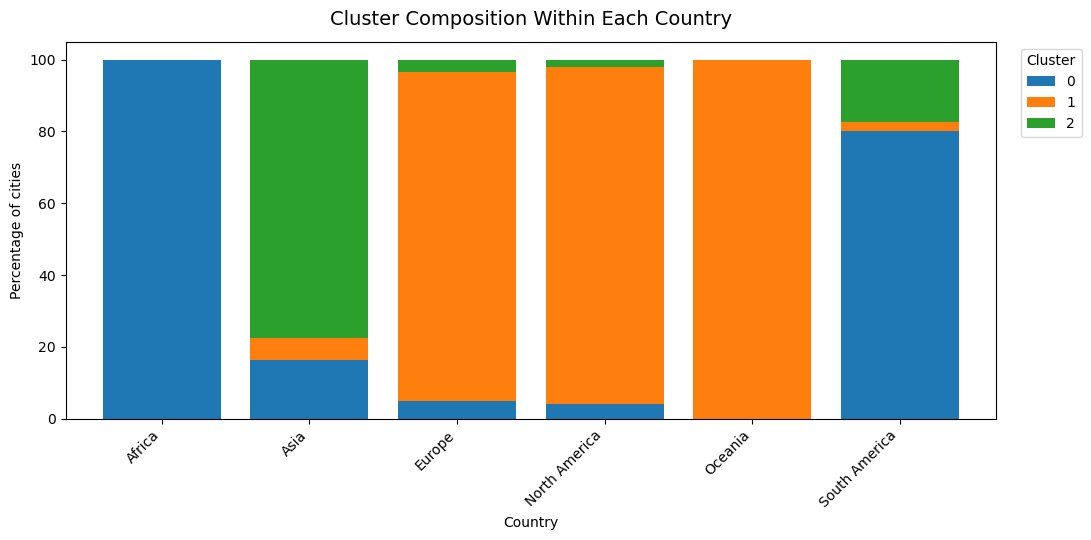

cluster,0,1,2
country,,,
Africa,100.0,0.0,0.0
Asia,16.2,6.2,77.5
Europe,5.0,91.7,3.3
North America,4.0,94.0,2.0
Oceania,0.0,100.0,0.0
South America,80.0,2.5,17.5


In [49]:
# Within-country cluster composition as percentages
country_share = pd.crosstab(
    df["country"],
    df["cluster"],
    normalize="index"
) * 100

ax = country_share.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5.5),
    width=0.8
)

ax.set_title("Cluster Composition Within Each Country", fontsize=14, pad=12)
ax.set_xlabel("Country")
ax.set_ylabel("Percentage of cities")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(country_share.round(1))


In [18]:
country_cluster = pd.crosstab(df["country"], df["cluster"])
display(country_cluster)

chi2, p_value, dof, expected = chi2_contingency(country_cluster)

n = country_cluster.to_numpy().sum()
r, c = country_cluster.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.3e}")
print(f"Cramer's V: {cramers_v:.3f}")


cluster,0,1,2
country,,,
Africa,35,0,0
Asia,13,5,62
Europe,3,55,2
North America,2,47,1
Oceania,0,35,0
South America,32,1,7


Chi-square statistic: 400.413
Degrees of freedom: 10
p-value: 7.689e-80
Cramer's V: 0.817


### Geographic interpretation

The cluster distribution varies substantially across continents. Africa and South America are concentrated mainly in Cluster 0, Europe, North America and Oceania are concentrated mainly in Cluster 1, while Asia is predominantly represented in Cluster 2. The chi-square test confirms that this association is statistically significant, and Cramer's V of 0.817 indicates a strong relationship between geographical region and cluster membership. Overall, the identified city-lifestyle clusters show a strong geographical pattern.

## 15. Representative cities and unusual observations

Cluster averages tell us what a cluster looks like, but we can make the result more tangible by finding:

1. the city closest to each K-Means centroid — a **representative city**;
2. the cities farthest from their assigned centroid — **atypical observations within their cluster**.

These are descriptive diagnostics, not formal anomaly-detection claims.


In [52]:
# Calculate each city's distance from its assigned K-Means centroid
distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[cluster_labels],
    axis=1
)

df["distance_to_centroid"] = distances


# ---------------------------------------------------------
# Representative city for each cluster
# ---------------------------------------------------------

representatives = []

for cluster in sorted(df["cluster"].unique()):
    subset = df[df["cluster"] == cluster]
    
    # City closest to the cluster centroid
    idx = subset["distance_to_centroid"].idxmin()
    
    representatives.append({
        "cluster": cluster,
        "representative_city": df.loc[idx, "city_name"],
        "country": df.loc[idx, "country"],
        "distance_to_centroid": df.loc[idx, "distance_to_centroid"]
    })

representatives = pd.DataFrame(representatives)

print("Most representative city in each cluster:")
display(representatives.round(3))


# ---------------------------------------------------------
# Most atypical cities within each cluster
# ---------------------------------------------------------

from IPython.display import display, HTML

atypical_tables = []

for cluster in sorted(df["cluster"].unique()):
    
    cols = ["city_name", "country", "distance_to_centroid"]
    
    atypical = (
        df[df["cluster"] == cluster]
        .sort_values("distance_to_centroid", ascending=False)[cols]
        .head(5)
        .round(3)
    )
    
    atypical_tables.append(
        (f"Cluster {cluster}", atypical)
    )


# Display all three tables side-by-side
html = """
<div style="
    display: flex;
    gap: 30px;
    align-items: flex-start;
    width: 100%;
">
"""

for title, table in atypical_tables:
    html += f"""
    <div style="flex: 1; min-width: 0;">
        <h4 style="text-align:center; margin-bottom:10px;">
            {title}
        </h4>
        {table.to_html(index=False)}
    </div>
    """

html += "</div>"

print("Most atypical observations within each cluster:")
display(HTML(html))

Most representative city in each cluster:


,cluster,representative_city,country,distance_to_centroid
0,0,Gardenville,South America,0.713
1,1,Woodport,Europe,0.394
2,2,Lake Bay,Asia,0.657


Most atypical observations within each cluster:


city_name,country,distance_to_centroid
North River,Africa,2.969
Old Bay,Africa,2.926
San Hill,Africa,2.669
West Harbor,Africa,2.523
Valleyhaven,Africa,2.474
city_name,country,distance_to_centroid
Townville,North America,3.762
Vistaville,North America,3.116
Stone,Europe,3.086
Valley,North America,2.930


## 16. Final project conclusion

### Main findings

- The city-lifestyle variables exhibit meaningful multivariate structure, making clustering appropriate for identifying groups of cities with similar profiles.
- Standardisation was necessary because the variables are measured on different scales.
- PCA shows that the first two components explain 79.6% of the standardised variation, providing a useful 2D representation for visualising the clusters. The scree plot was used to retain three principal components for the broader PCA analysis.
- For K-Means, K = 3 provides the strongest overall validation among the solutions tested and is therefore selected as the final clustering solution.
- The final K-Means solution identifies three distinct city-lifestyle profiles, differing particularly in income, happiness, population density, internet penetration, rent and environmental conditions.
- Ward hierarchical clustering was evaluated independently and selected K = 2 as its best solution. The best K-Means solution outperformed the best Ward solution across the three internal validation measures.
- The K = 3 K-Means solution is stable across repeated random initialisations, supporting the reliability of the resulting segmentation.
- A strong association was found between continent and cluster membership in the post-clustering analysis, suggesting that the identified city-lifestyle profiles also reflect geographical patterns.
